Ouvrir ce notebook dans :
<a href="https://colab.research.google.com/github/joanglaunes/algosto/blob/master/python/gradient_gradient_sto_log_erreur.ipynb" target="_blank">Google Colab</a>
ou
<a href="https://rosenblatt.ens.math-info.univ-paris5.fr/hub/user-redirect/git-pull?repo=https%3A%2F%2Fgithub.com%2Fjoanglaunes%2Falgosto&urlpath=tree%2Falgosto%2Fpython%2Fgradient_gradient_sto_log_erreur.ipynb&branch=master" target="_blank">Rosenblatt</a>


# Comparaison des vitesses de convergence entre la descente de gradient et la descente de gradient stochastique

In [2]:
import numpy as np
import matplotlib.pyplot as plt

On va chercher à comparer les vitesses de convergence de la decente de gradient classique et de la descente de gradient stochastique, sur l'exemple simple de la régression linéaire où les solutions du probléme sont explicites.

On se place donc dans la situation de l'exerice 1 du TP (voir fichier TP_gradient_stochatique.ipynb).
Recréons d'abord les données $x_i$ et $y_i$:

In [3]:
N = int(1e3)
x = np.random.rand(N,1)
sigma = 0.1
y = x + 1 + sigma*np.random.randn(x.shape[0],x.shape[1])

La fonction à minimiser est
$$J(a,b) = \frac 1 N \sum_{i=1}^N (y_i - a x_i -b)^2$$
Les solutions explicites de ce problème sont
$$a^* = \frac{m_{xy}-m_xm_y}{m_{x^2}-m_x^2},\qquad b^* = m_y - m_x a^*$$
où on a noté
$m_{xy}=\frac1N\sum_{i=1}^Nx_iy_i,\quad m_{x}=\frac1N\sum_{i=1}^Nx_i,\quad m_{y}=\frac1N\sum_{i=1}^Ny_i
,\quad m_{x^2}=\frac1N\sum_{i=1}^Nx_i^2.$
Calculons ces quantités et affichons les données avec la droite de régression optimale :

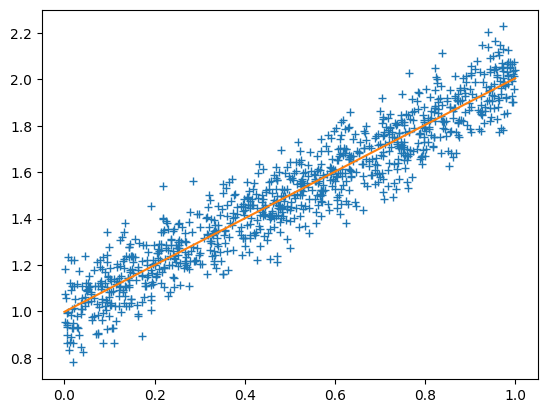

In [5]:
a_opt = (np.mean(x*y)-np.mean(x)*np.mean(y)) / (np.mean(x**2)-np.mean(x)**2)
b_opt = np.mean(y) - np.mean(x)*a_opt

plt.plot(x,y,'+');
plt.plot([0,1],[b_opt,a_opt+b_opt]);

Définissons la fonction $J$, son gradient, et une fonction pour effectuer une descente de gradient classique:

In [11]:
J = lambda a,b : 1/(x.shape[0])*np.sum((a*x+b-y)**2)

GradJ = lambda a,b : (2*np.mean(x*(a*x+b-y)), 2*np.mean(a*x+b-y))

def descente_gradient(a0,b0,rho,niter):
    a,b = a0,b0
    cout = np.zeros(niter)
    for k in range(niter):
        dJa, dJb = GradJ(a,b)
        a = a - rho*dJa
        b = b - rho*dJb
        cout[k] = J(a,b)
    return a, b, cout

Maintenant on peut lancer plusieurs essais de descentes de gradient en partant d'initialisations différentes. On affiche
à chaque fois le logarithme de l'erreur $\log_{10}(J(a,b)-J(a^*,b^*))$ en fonction des itérations, ainsi que la moyenne sur tous les essais.

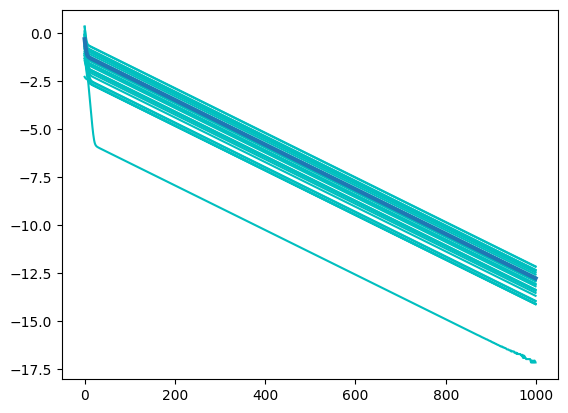

In [18]:
L    = 30                                           # nombre d'experiences
niter = 1000                                        # nombre d'iterations de la descente
rho   = 0.1                                         # pas

cout_gd_mean = np.zeros(niter)
for k in range(L):
    a0,b0 = 1+np.random.randn(),1+np.random.randn()
    a,b,cout_gd = descente_gradient(a0,b0,rho,niter)
    # Courbe du log de l'erreur:
    plt.plot(np.log10(cout_gd-J(a_opt,b_opt)),'c')
    cout_gd_mean += cout_gd
cout_gd_mean /= L
plt.plot(np.log10(cout_gd_mean-J(a_opt,b_opt)), linewidth=3);

Faisons la même chose pour le gradient stochastique à présent:

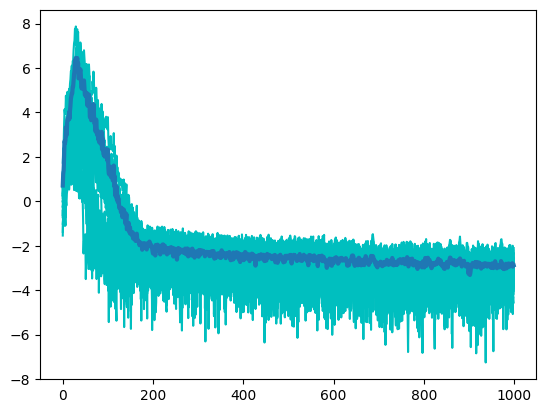

In [22]:
Gradf = lambda a,b,i_k : (2*(x[i_k]*(a*x[i_k]+b-y[i_k])), 2*(a*x[i_k]+b-y[i_k]))

def descente_gradient_stochastique(a0,b0,alpha,beta,niter):
    a,b = a0,b0
    cout = np.zeros(niter)
    for k in range(niter):
        rho_k = alpha / (beta*k+1)
        i_k = np.random.randint(N)
        dfa, dfb = Gradf(a,b,i_k)
        a = a - rho_k*dfa
        b = b - rho_k*dfb
        cout[k] = J(a,b)
    return a, b, cout

L    = 30                                           # nombre d'experiences
niter = 1000                                        # nombre d'iterations de la descente
alpha, beta = 1, 0.01

cout_gds_mean = np.zeros(niter)
for k in range(L):
    a0,b0 = 1+np.random.randn(),1+np.random.randn()
    a,b,cout_gds = descente_gradient_stochastique(a0,b0,alpha,beta,niter)
    # Courbe du log de l'erreur:
    plt.plot(np.log10(cout_gds-J(a_opt,b_opt)),'c')
    cout_gds_mean += cout_gds
cout_gds_mean /= L
plt.plot(np.log10(cout_gds_mean-J(a_opt,b_opt)), linewidth=3);

Enfin on va comparer ces deux courbes d'erreurs, mais en tenant compte
du coût de calcul : une itération de gradient classique équivaut à N itérations
de gradient stochastique. Ici N=1000, donc 1000 itérations de descente de gradient stochastique équivallent
à 1 iteration de descente de gradient classique. Pour pouvoir comparer, on doit donc refaire les expériences en effectuant
1000 fois plus d'itérations pour le gradient stochastique. On va choisir de faire 1000 itérations pour le gradient classique,
et 1000000 itérations pour le gradient stochastique.

__Remarque__: Du fait du grand nombre d'itérations du gradient stochastique, le code ci-dessous est très long à s'exécuter, alors que la partie descente de gradient classique reste très rapide. Ceci pourrait paraître paradoxal en fait, puisque le but est de comparer les algorithmes pour des coûts de calcul équivalents. Mais il y a deux explications: premièrement, ici on calcule la valeur de la fonction $J(a,b)$ à l'intérieur de la boucle d'itération, ce qui est nécessaire pour afficher les taux d'erreur à la fin, mais rajoute dans les deux cas des calculs en $O(N)$ à chaque itération. Ensuite, du fait de l'implémentation de NumPy, les calculs effectués sur les vecteurs (ici x et y) sont extrêment rapides, de plusieurs ordres de grandeur par rapport à la boucle Python des itérations, qui elle n'est pas vectorisable car il s'agit d'un calcul récursif. C'est pour cette raison que le gradient stochastique est toujours remplacé en pratique par des versions par mini-batchs, donc intermédaires entre gradient classique et stochastique, afin de profiter au maximum de l'efficacité des calculs vectorisés.

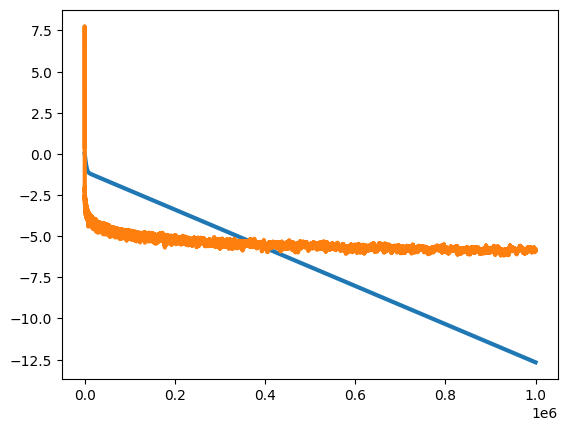

In [28]:
L = 30

# L essais de descente de gradient classique avec niter=1e3
niter_gd = 1000
cout_gd_mean = np.zeros(niter_gd)
for k in range(L):
    a0,b0 = 1+np.random.randn(),1+np.random.randn()
    a,b,cout_gd = descente_gradient(a0,b0,rho,niter_gd)
    cout_gd_mean += cout_gd
cout_gd_mean /= L

# L essais de descente de gradient classique avec niter=1e6
niter_gds = niter_gd * N
cout_gds_mean = np.zeros(niter_gds)
for k in range(L):
    a0,b0 = 1+np.random.randn(),1+np.random.randn()
    a,b,cout_gds = descente_gradient_stochastique(a0,b0,alpha,beta,niter_gds)
    cout_gds_mean += cout_gds
cout_gds_mean /= L

# on affiche 
plt.plot(np.linspace(0,niter_gds,niter_gd),np.log10(cout_gd_mean-J(a_opt,b_opt)), linewidth=3)
plt.plot(np.log10(cout_gds_mean-J(a_opt,b_opt)), linewidth=3);